## Output saving notebook
This notebook saves all outputs to the QualityCheckPassed and QualityCheckPassedRealBackground folders. Please carefully read each cell. Places where you might want to change a parameter's value are marked with a "#! NOTE: maybe change" comment, followed by a short explanation. The values that you choose for these variables probably depend on the results in earlier steps in the notebook.

In [1]:
import numpy as np
from skimage.registration import phase_cross_correlation
import PIL
from PIL import Image
import os
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import shift as shift_image
from scipy.io import savemat, loadmat

In [2]:
import skimage
skimage.__version__

'0.18.1'

In [3]:
# please do not change these values!
channels = ['DIA-Ph3', 'DAPI2', 'FITC3', 'TRITC-1']  # dapi, brightfield, fitc (actin), tritc (YAP)
PIL.Image.MAX_IMAGE_PIXELS = 509252135 + 1  # to allow opening large image files
MAX_PIXEL_VALUE = 65535

In [4]:
# load the data

# fixed image background:
fixed_image_files = os.listdir('Input/FixedImages/')
assert len(fixed_image_files) == 1, 'ERROR: There should be only one fixed image. Do not proceed before fixing!'
fixed_image = np.array(Image.open('Input/FixedImages/' + fixed_image_files[0])) #

# tables:
table_path = 'Output/CP_Output_Koen/Excel/outliersRemoved_Actin.csv'
table = pd.read_csv(table_path, index_col=0)

# big raw image files (pray to the gods you have enough RAM free):

raw_imgs = {}
for c in tqdm(channels):
    f = os.path.join('Input', 'RawData', 'ChannelTRITC-1,FITC3,DIA-Ph3,DIA-Ph4,DAPI2_Seq0000_'+ c + '.tif', )
    img = Image.open(f)
    raw_imgs[c] = np.array(img) #/ MAX_PIXEL_VALUE * 255).astype('uint8')
    



  0%|          | 0/4 [00:00<?, ?it/s]

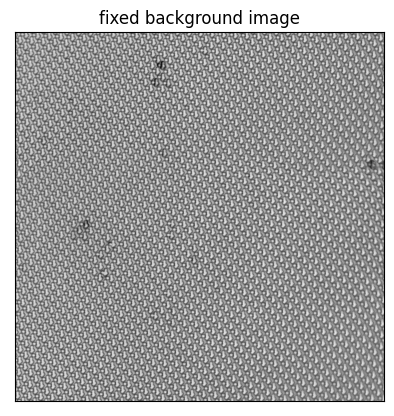

In [5]:
plt.figure()
plt.imshow(fixed_image, cmap='gray')
plt.title('fixed background image')
plt.xticks([])
plt.yticks([])
plt.show()


In [6]:
# for each entry in the table, define the x_min/x_max pixels through looking at the NW_xx of the entry, 
# and the center location of the cell relative to the NW coordinates. (NW=north-west)
# We can extract the cropped image then through the size of the fixed pattern and this center location

In [7]:
# get some info from the table:
h, w = fixed_image.shape
assert h == w, 'only tested for h==w -- if this is not true, please verify the matching of h and w to x and y'
#
center_x, center_y = table.Location_Center_X + table.Metadata_NW_XX, table.Location_Center_Y +  table.Metadata_NW_YY
x_min, x_max, y_min, y_max = center_x - w //2, center_x + w //2, center_y - h //2, center_y + h //2

if h % 2 != 0: # uneven, add a pixel to the right and bottom to ensure equal sizes of fixed patterns and crops:
    x_max += 1
    y_max += 1

table['x_min'] = x_min.astype(int)
table['x_max'] = x_max.astype(int)
table['y_min'] = y_min.astype(int)
table['y_max'] = y_max.astype(int)

# also get the bounding box information of each cell to mask out any contributions from cells closeby:
table['x_bbox_min'] = table.AreaShape_BoundingBoxMinimum_X + table.Metadata_NW_XX
table['x_bbox_max'] = table.AreaShape_BoundingBoxMaximum_X + table.Metadata_NW_XX
table['y_bbox_min'] = table.AreaShape_BoundingBoxMinimum_Y + table.Metadata_NW_YY
table['y_bbox_max'] = table.AreaShape_BoundingBoxMaximum_Y + table.Metadata_NW_YY




In [8]:
# define the utility functions for aligning the cell image within the bounding box on the larger background image:

def align_bboxed_image_on_bg(row):
    # get the upper left coordinates of the cell's bbox relative to the larger background image
    # and also get the height/width of the bounding box
    upper_left_y = row.y_bbox_min - row.y_min
    upper_left_x = row.x_bbox_min - row.x_min
    h_bbox = row.y_bbox_max - row.y_bbox_min
    w_bbox = row.x_bbox_max - row.x_bbox_min
    return upper_left_y, upper_left_x, h_bbox, w_bbox

        
def get_cropped_cell_and_bg(row, raw_imgs, channels, bg_fixed=None):
    # get a 4-channel image with the background and cell stains
    # here, the cell stains are restricted to within the cell's bbox, and 0 elsewhere

    # initialize the cropped image with zeros:
    img_cropped = np.zeros(shape=(row.y_max - row.y_min, row.x_max - row.x_min, 4))
    for channel_counter, c in enumerate(channels):
        if c == 'DIA-Ph3': # background -- covers the full image
            if bg_fixed is None: # get the bg from the raw img
                img_cropped[..., channel_counter] += raw_imgs[c][row.y_min:row.y_max, row.x_min:row.x_max]
                
            else: # use the custom provided bg (fixed bg that we aligned on) -- must be same shape as img_cropped
                img_cropped[..., channel_counter] += bg_fixed
                
        else: # take only the part within the bbox for the cell stain channels and align on the full bg image:
            cell_bboxed = raw_imgs[c][row.y_bbox_min:row.y_bbox_max, row.x_bbox_min:row.x_bbox_max]
            upper_left_y, upper_left_x, h_bbox, w_bbox = align_bboxed_image_on_bg(row)
            img_cropped[upper_left_y:upper_left_y+h_bbox, upper_left_x:upper_left_x+w_bbox, channel_counter] += cell_bboxed
            
    return img_cropped



def plot_cell_img_and_bg(img_cropped, bg_illumination_scaling=0.7):
    # get the 4-channel cropped image with background and cell stains and convert to 3-channel image for plotting
    
    # initialize 3-channel image for plotting:
    to_plot = np.zeros(shape=(*img_cropped.shape[:-1], 3))
    to_plot += (img_cropped[..., 0:1] * bg_illumination_scaling)
    to_plot += img_cropped[..., 1:]       
    to_plot = np.minimum(to_plot, MAX_PIXEL_VALUE)
    
    return to_plot

def normalize(img):
    return (img - np.min(img)) / (np.max(img) - np.min(img))

In [9]:
### optionally, we can plot a few test images to make sure we get the cropping right before saving
### note: later we will load some actual saved images for verification

# bg_illumination_scaling = 0.8


# idx_to_plot = np.random.randint(0, table.shape[0], 9)
# fig, axs = plt.subplots(3,3, figsize=(10, 10))
# for i, ax in enumerate(axs.reshape(-1)):
#     row = table.iloc[random_idx[i]]
#     img_cropped = get_cropped_cell_and_bg(row, raw_imgs, channels)
#     to_plot = plot_cell_img_and_bg(img_cropped, bg_illumination_scaling=bg_illumination_scaling)
#     # normalize for visualization purposes:
#     to_plot = normalize(to_plot)
#     ax.imshow(to_plot)
#     ax.set_xticks([])
#     ax.set_yticks([])

# plt.tight_layout()
# plt.show()
             

In [10]:
# write out the images on the real background to QualityCheckPassedRealBackground
# also plot a few of the images to visually verify the output

save_dir_real_bg = os.path.join('Output', 'QualityCheck', 'QualityCheckPassedRealBackground')
if not os.path.exists(save_dir_real_bg):
    print('directory not found -- creating the directory...')
    os.makedirs(save_dir_real_bg)

for i in tqdm(range(table.shape[0])):
    row = table.iloc[i]
    try:
        img_cropped = get_cropped_cell_and_bg(row, raw_imgs, channels)
        nucl_num = i+1
        filename = f'real_NucleiNr{nucl_num:04d}_TileNumber{row.Metadata_TileNumber:02d}.png.mat'
        savemat(os.path.join(save_dir_real_bg, filename), mdict={'I':img_cropped}, appendmat=False, do_compression=True)
#         print(filename)
    except Exception as e:
        print(f'error img {i} -- likely the cell bbox exceeds the dimensions of bg. Skipping...')
        print('exception:', str(e))


  0%|          | 0/536 [00:00<?, ?it/s]

error img 141 -- likely the cell bbox exceeds the dimensions of bg. Skipping...
exception: operands could not be broadcast together with shapes (751,3) (751,802) (751,3) 


loading and plotting some random saved images on real backgrounds for visual verification...


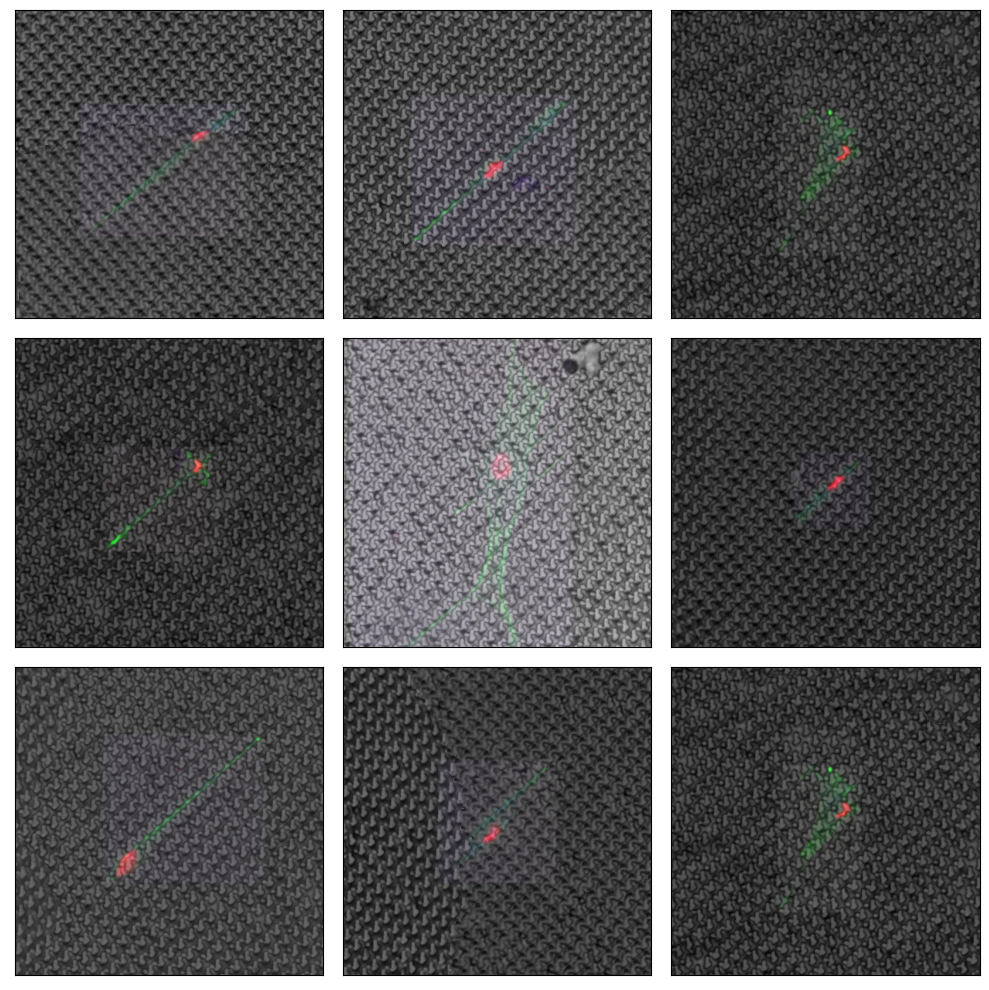

In [19]:
print('loading and plotting some random saved images on real backgrounds for visual verification...')

###! Note: maybe change depending on how much you want to zoom
pixels_from_center = 200  # set to None for no zooming

all_saved_files = os.listdir(save_dir_real_bg)
idx_to_plot = np.random.randint(0, len(all_saved_files), 9)

# plot a few test images to make sure we get the cropping right:
bg_illumination_scaling = 0.8


fig, axs = plt.subplots(3,3, figsize=(10, 10))
for i, ax in enumerate(axs.reshape(-1)):
    img_cropped = loadmat(os.path.join(save_dir_real_bg, all_saved_files[idx_to_plot[i]]))['I']
    to_plot = plot_cell_img_and_bg(img_cropped, bg_illumination_scaling=bg_illumination_scaling)
    # normalize for visualization purposes:
    to_plot = normalize(to_plot)
    c = to_plot.shape[0] // 2
    if pixels_from_center is not None:
        to_plot = to_plot[c-pixels_from_center:c+pixels_from_center, c-pixels_from_center:c+pixels_from_center]
    ax.imshow(to_plot)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [48]:
# now start the phase correlation alignment on the virtual background

#! NOTE: maybe change -- you may define here the pixel range from the center of the images that we consider for calculating
# the best alignment. for now, let's agree on the cropped image at 150 pixels left/right/above/below of the center
# set to None to consider the whole image
pc_image_range=150 # or None, or different int

In [49]:
# first, construct a table where we adjust the x_min, x_max information s.t. it corresponds to the alignment with the fixed bg:

table_aligned = table.copy()
fixed_img_bg = fixed_image 
all_errors = []
all_shifts = []

for idx in tqdm(range(table_aligned.shape[0])):
    # get the data from the table and image
    row = table_aligned.iloc[idx].copy()
    moving_img_bg = raw_imgs['DIA-Ph3'][row.y_min:row.y_max, row.x_min:row.x_max]
    
    # if we only consider a limited range for the pc alignment (to prevent excessive shifts),
    # calculate the crop for the image:
    if pc_image_range is not None:
        c_fixed = fixed_img_bg.shape[0] // 2
        low_fixed, high_fixed = c_fixed-pc_image_range, c_fixed+pc_image_range
        c_moving = moving_img_bg.shape[0] // 2
        low_moving, high_moving = c_moving-pc_image_range, c_moving+pc_image_range
    else:
        low_fixed, low_moving, high_fixed, high_moving = -np.inf, -np.inf, np.inf, np.inf
    
    # crop the image (if applicable)
    low_fixed = max(0, low_fixed)
    high_fixed = min(fixed_img_bg.shape[0], high_fixed)
    low_moving = max(0, low_moving)
    high_moving = min(moving_img_bg.shape[0], high_moving)
    fixed_img_bg_this = fixed_img_bg[low_fixed:high_fixed,
                                    low_fixed:high_fixed]
    moving_img_bg_this = moving_img_bg[low_moving:high_moving, low_moving:high_moving]
    
    # do the phase correlation:
    shift, error, phasediff = phase_cross_correlation(fixed_img_bg_this, moving_img_bg_this, 
                                                  reference_mask=None,
                                                  moving_mask=None)
    all_shifts.append(shift)
    all_errors.append(error)
    
    row.y_min -= shift[0]
    row.y_max -= shift[0]
    row.x_min -= shift[1]
    row.x_max -= shift[1]
    table_aligned.iloc[idx] = row
    
    

  0%|          | 0/536 [00:00<?, ?it/s]

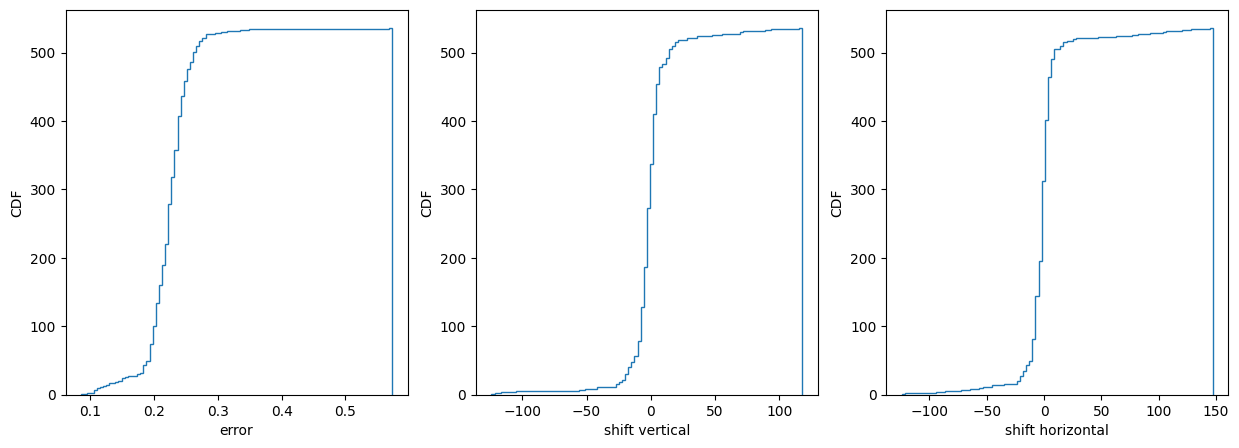

In [56]:
#now plot a few diagnostics:
fig, axs = plt.subplots(1,3, figsize=(15, 5))

axs[0].hist(all_errors, histtype='step', cumulative=True, bins=100)
axs[0].set_xlabel('error')
axs[0].set_ylabel('CDF')

axs[1].hist(list(map(lambda x: x[0], all_shifts)), histtype='step', cumulative=True, bins=100)
axs[1].set_xlabel('shift vertical')
axs[1].set_ylabel('CDF')

axs[2].hist(list(map(lambda x: x[1], all_shifts)), histtype='step', cumulative=True, bins=100)
axs[2].set_xlabel('shift horizontal')
axs[2].set_ylabel('CDF')

plt.show()


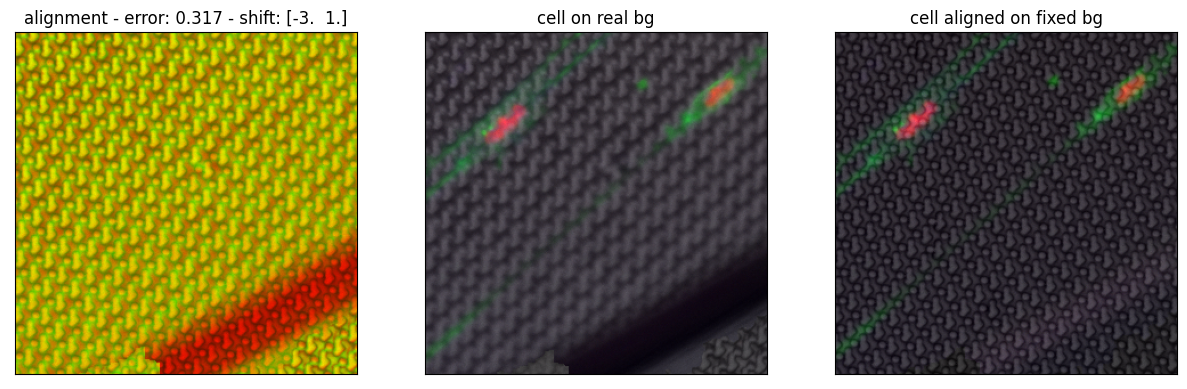

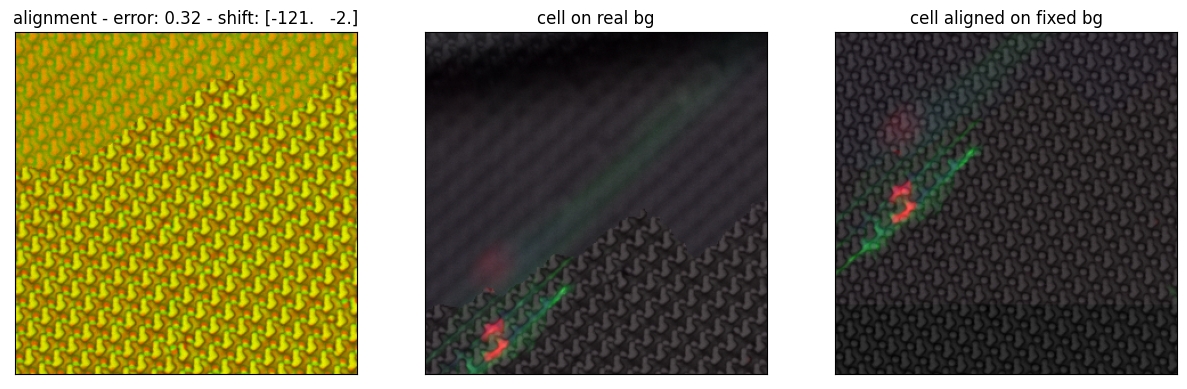

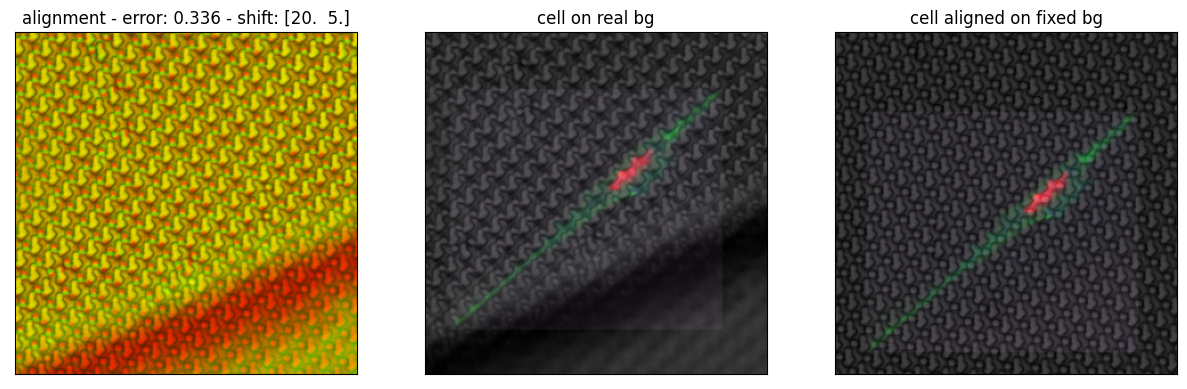

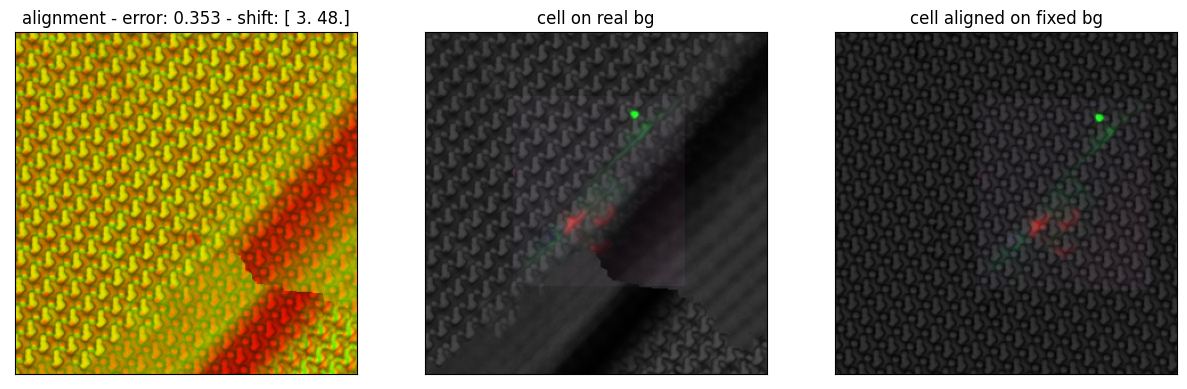

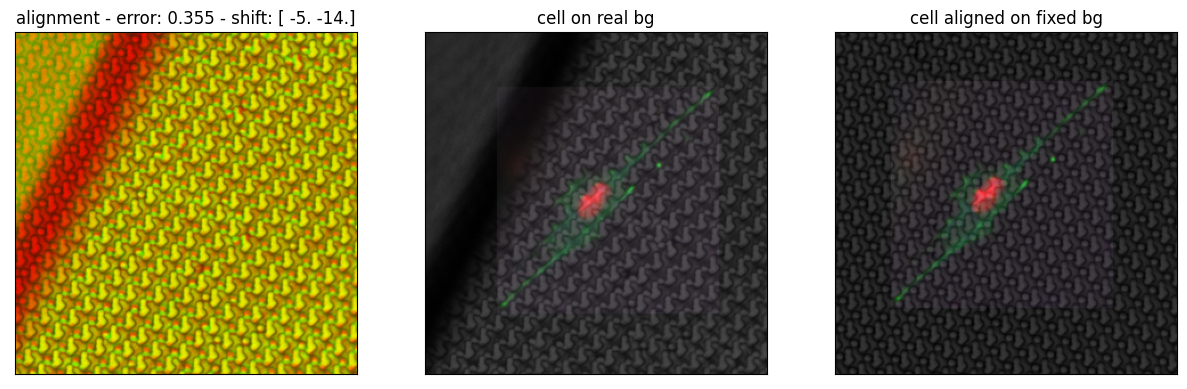

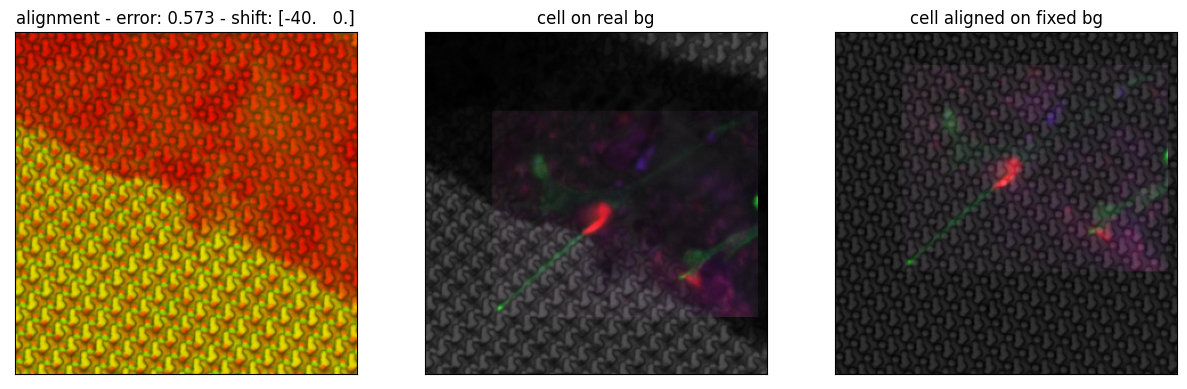

In [57]:
# visual inspection

#! NOTE: maybe change -- choose the number of imgs you want to visually inspect:
num_idx_to_plot = 6
#! NOTE: maybe change -- choose which images you want to plot. 'uniform' or 'worst'
plot_selection = 'worst'  # 'uniform' for selecting images with good and bad errors, 'worst' for selecting the worst images
###! Note: maybe change depending on how much you want to zoom
pixels_from_center = 150  # set to None for no zooming

# get the idx to plot: (#! NOTE: maybe change -- you can also adjust here which idx you want to visualize manually...)
errors_sort_idx = np.argsort(all_errors) # in ascending order
if plot_selection == 'uniform':
    idx_to_get_from_argsort = np.round(np.linspace(0, len(errors_sort_idx) - 1, num_idx_to_plot)).astype(int)
elif plot_selection == 'worst':
    idx_to_get_from_argsort = list(reversed([-i for i in range(1, num_idx_to_plot+1)]))
idx_to_plot = errors_sort_idx[idx_to_get_from_argsort]

############
############

bg_illumination_scaling=0.5
for idx in idx_to_plot:
    fig, axs = plt.subplots(1,3, figsize=(15,15))
    
    # get the right images:
    row_original = table.iloc[idx].copy()
    row_shifted = table_aligned.iloc[idx].copy()
    moving_img_shifted = raw_imgs['DIA-Ph3'][row_shifted.y_min:row_shifted.y_max, row_shifted.x_min:row_shifted.x_max]

    # now plotting code:
    verify = np.zeros(shape=(*fixed_img_bg.shape, 3))
    verify[...,0] = fixed_img_bg
    verify[...,1] = moving_img_shifted
    c = verify.shape[0] // 2
    if pixels_from_center is not None:
        verify = verify[c-pixels_from_center:c+pixels_from_center, c-pixels_from_center:c+pixels_from_center]
    axs[0].imshow(normalize(verify))
    axs[0].set_title(f'alignment - error: {np.round(all_errors[idx], 3)} - shift: {all_shifts[idx]}')

    img_cropped = get_cropped_cell_and_bg(row_original, raw_imgs, channels)
    cell_and_bg = plot_cell_img_and_bg(img_cropped, bg_illumination_scaling)
    c = cell_and_bg.shape[0] // 2
    if pixels_from_center is not None:
        cell_and_bg = cell_and_bg[c-pixels_from_center:c+pixels_from_center, c-pixels_from_center:c+pixels_from_center]
    axs[1].imshow(normalize(cell_and_bg))
    axs[1].set_title('cell on real bg')

    img_cropped_moved = get_cropped_cell_and_bg(row_shifted, raw_imgs, channels, bg_fixed=fixed_image)
    cell_and_bg_moved = plot_cell_img_and_bg(img_cropped_moved, bg_illumination_scaling) 
    c = cell_and_bg_moved.shape[0] // 2
    if pixels_from_center is not None:
        cell_and_bg_moved = cell_and_bg_moved[c-pixels_from_center:c+pixels_from_center,
                                              c-pixels_from_center:c+pixels_from_center]
    axs[2].imshow(normalize(cell_and_bg_moved))
    axs[2].set_title('cell aligned on fixed bg')


    for ax in axs.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    plt.show()


In [30]:
#! NOTE: maybe change -- you may define here the largest idx that you still want to save (sorted ascending on error)

save_until_idx = table_aligned.shape[0] # set to table_aligned.shape[0] to save all images



In [31]:
# write out the images on the fixed background to QualityCheckPassed

save_dir_fixed_bg = os.path.join('Output', 'QualityCheck', 'QualityCheckPassed')
if not os.path.exists(save_dir_real_bg):
    print('directory not found -- creating the directory...')
    os.makedirs(save_dir_fixed_bg)

for ii in tqdm(range(save_until_idx)):
    i = errors_sort_idx[ii]
    row = table_aligned.iloc[i]
    shift = all_shifts[i]
#     if abs(shift[0]) > max_shift or abs(shift[1]) > max_shift:
#         print(f'skipping index {i} due to too large shift!')
#         continue
    try:
        img_cropped = get_cropped_cell_and_bg(row, raw_imgs, channels, bg_fixed=fixed_image)
        nucl_num = i+1
        filename = f'reconstruction_NucleiNr{nucl_num:04d}.png.mat'
        savemat(os.path.join(save_dir_fixed_bg, filename), mdict={'I':img_cropped}, appendmat=False, do_compression=True)
#         print(filename)
    except Exception as e:
        print(f'error img {i} -- likely the cell bbox exceeds the dimensions of bg. skipping...')
        print('exception:', str(e))


  0%|          | 0/536 [00:00<?, ?it/s]

skipping index 492 due to too large shift!
skipping index 515 due to too large shift!
skipping index 522 due to too large shift!
skipping index 521 due to too large shift!
skipping index 526 due to too large shift!
skipping index 514 due to too large shift!
skipping index 525 due to too large shift!
skipping index 509 due to too large shift!
skipping index 0 due to too large shift!
skipping index 533 due to too large shift!
skipping index 518 due to too large shift!
skipping index 482 due to too large shift!
skipping index 507 due to too large shift!
skipping index 519 due to too large shift!
skipping index 20 due to too large shift!
error img 94 -- likely the cell bbox exceeds the dimensions of bg. skipping...
exception: operands could not be broadcast together with shapes (0,288) (704,288) (0,288) 
skipping index 524 due to too large shift!
skipping index 52 due to too large shift!
skipping index 93 due to too large shift!
skipping index 158 due to too large shift!
skipping index 11 

KeyboardInterrupt: 

loading and plotting some random saved images on fixed background for visual verification...


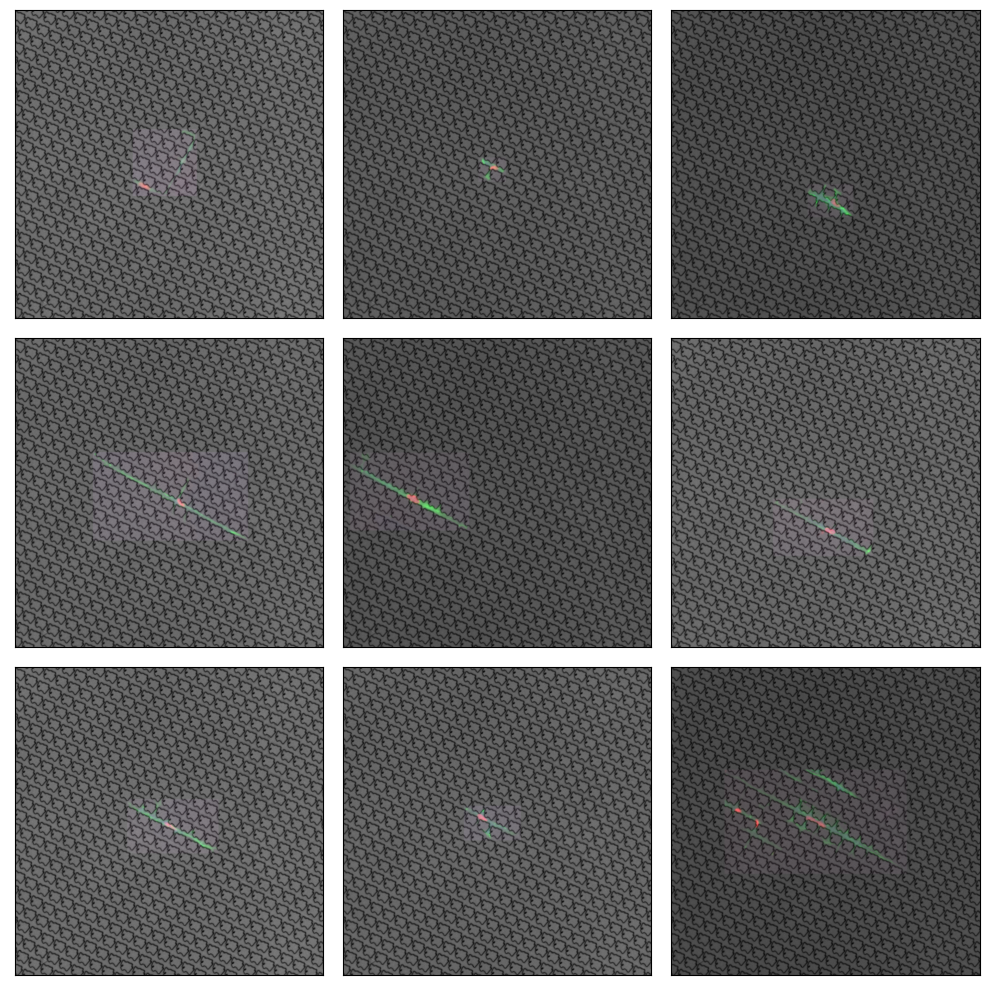

In [23]:
print('loading and plotting some random saved images on fixed background for visual verification...')
all_saved_files = os.listdir(save_dir_fixed_bg)
idx_to_plot = np.random.randint(0, len(all_saved_files), 9)

# plot a few test images to make sure we get the cropping right:
bg_illumination_scaling = 0.8


fig, axs = plt.subplots(3,3, figsize=(10, 10))
for i, ax in enumerate(axs.reshape(-1)):
    img_cropped = loadmat(os.path.join(save_dir_fixed_bg, all_saved_files[idx_to_plot[i]]))['I']
    to_plot = plot_cell_img_and_bg(img_cropped, bg_illumination_scaling=bg_illumination_scaling)
    # normalize for visualization purposes:
    to_plot = normalize(to_plot)
    ax.imshow(to_plot)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


In [436]:
idx = 11
row = table.iloc[idx].copy()
fixed_img_bg = fixed_image / 255.


upper_left_y, upper_left_x, h_bbox, w_bbox = align_bboxed_image_on_bg(row)


moving_img_bg = raw_imgs['DIA-Ph3'][row.y_min:row.y_max, row.x_min:row.x_max] / 255.
moving_img_mask = None#np.zeros_like(moving_img_bg)
fixed_img_mask = None#np.zeros_like(fixed_img_bg)
# moving_img_mask[upper_left_y:upper_left_y+h_bbox, upper_left_x:upper_left_x+w_bbox] = 1
# fixed_img_mask[upper_left_y:upper_left_y+h_bbox, upper_left_x:upper_left_x+w_bbox] = 1

shift = phase_cross_correlation(fixed_img_bg, moving_img_bg, 
                                                  reference_mask=fixed_img_mask,
                                                  moving_mask=moving_img_mask)
if isinstance(shift, tuple):
    shift = shift[0]
shift = shift.astype(int)
# print('shift:', shift, 'error:', error)
print('shift:', shift)

moving_img_shifted = shift_image(moving_img_bg, shift)




shift: [-15  22]


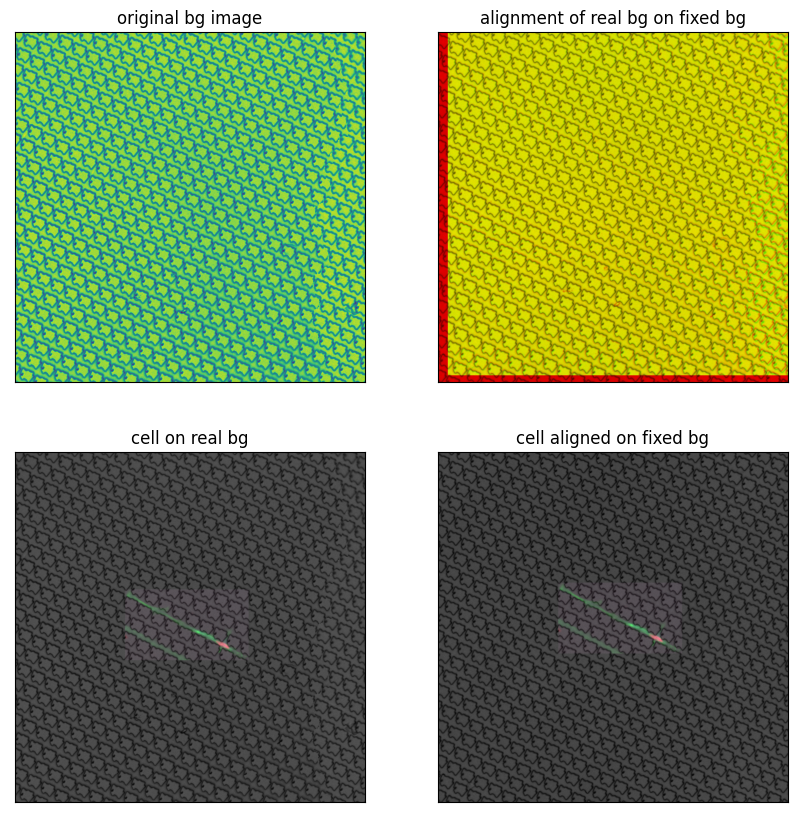

In [437]:
# plot example image to test alignment

bg_illumination_scaling=0.5

fig, axs = plt.subplots(2, 2, figsize=(10,10))

axs[0,0].imshow(moving_img_bg)
axs[0,0].set_title('original bg image')
verify = np.zeros(shape=(*fixed_img_bg.shape, 3))
verify[...,0] = fixed_img_bg
verify[...,1] = moving_img_shifted
axs[0,1].imshow(normalize(verify))
axs[0,1].set_title('alignment of real bg on fixed bg')

img_cropped = get_cropped_cell_and_bg(row, raw_imgs, channels)
cell_and_bg = plot_cell_img_and_bg(img_cropped, bg_illumination_scaling)
axs[1,0].imshow(normalize(cell_and_bg))
axs[1,0].set_title('cell on real bg')


row_with_shift = row.copy()

# row_with_shift.y_bbox_min += shift[0]
# row_with_shift.y_bbox_max += shift[0]
row_with_shift.y_min -= shift[0]
row_with_shift.y_max -= shift[0]

# row_with_shift.x_bbox_min += shift[1]
# row_with_shift.x_bbox_max += shift[0]
row_with_shift.x_min -= shift[1]
row_with_shift.x_max -= shift[1]


img_cropped_moved = get_cropped_cell_and_bg(row_with_shift, raw_imgs, channels, bg_fixed=fixed_image)
cell_and_bg_moved = plot_cell_img_and_bg(img_cropped_moved, bg_illumination_scaling) 
axs[1,1].imshow(normalize(cell_and_bg_moved))
axs[1,1].set_title('cell aligned on fixed bg')


for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()


In [142]:
# plt.imshow(fixed_img_bg)
# plt.show()
# plt.imshow(moving_img_bg)
# plt.show()

# plt.hist(fixed_img_bg.flat)
# plt.show()
# plt.hist(moving_img_bg.flat)
# plt.show()

print(fixed_img_bg.shape)
print(moving_img_bg.shape)

(785, 785)
(785, 785)


In [150]:
np.unique(verify)

array([0.        , 0.01176471, 0.01176471, 0.01176471, 0.01176471,
       0.01568627, 0.01568627, 0.01568627, 0.01568627, 0.01960784,
       0.01960784, 0.01960784, 0.01960784, 0.01960784, 0.01960784,
       0.01960784, 0.02352941, 0.02352941, 0.02352941, 0.02352941,
       0.02352941, 0.02352941, 0.02352941, 0.02352941, 0.02352941,
       0.02745098, 0.02745098, 0.02745098, 0.02745098, 0.02745098,
       0.02745098, 0.02745098, 0.02745098, 0.02745098, 0.02745098,
       0.03137255, 0.03137255, 0.03137255, 0.03137255, 0.03137255,
       0.03529412, 0.03529412, 0.03529412, 0.03529412, 0.03529412,
       0.03529412, 0.03529412, 0.03921569, 0.03921569, 0.03921569,
       0.03921569, 0.03921569, 0.03921569, 0.03921569, 0.04313725,
       0.04313725, 0.04313725, 0.04313725, 0.04313725, 0.04313725,
       0.04313725, 0.04705882, 0.04705882, 0.04705882, 0.04705882,
       0.04705882, 0.04705882, 0.04705882, 0.04705882, 0.04705882,
       0.05098039, 0.05098039, 0.05098039, 0.05098039, 0.05098

In [151]:
np.unique(fixed_img_bg)

array([0.01568627, 0.01960784, 0.02352941, 0.02745098, 0.03137255,
       0.03529412, 0.03921569, 0.04313725, 0.04705882, 0.05098039,
       0.05490196])

In [116]:
table.iloc[0][['y_min', 'y_max', 'y_bbox_min', 'y_bbox_max', 'x_min', 'x_max', 'x_bbox_min', 'x_bbox_max']]

y_min         2677
y_max         3461
y_bbox_min    3020
y_bbox_max    3123
x_min         6349
x_max         7133
x_bbox_min    6645
x_bbox_max    6827
Name: 0, dtype: object